In [1]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

sys.path.insert(0, str(PROJECT_ROOT))

import torch
import torch.nn as nn
import matplotlib.pyplot as plt

from torch.optim import Adam
from torch.utils.data import DataLoader

from datasets.coin_detection_dataset import CoinDetectionDataset
from datasets.preprocessing import prepare_dataset
from models.money_classifier import MoneyClassifier

device = torch.device("mps")

CHECKPOINT_DIR = PROJECT_ROOT / "checkpoints"
CHECKPOINT_DIR.mkdir(exist_ok=True)

In [ ]:
train_ds = CoinDetectionDataset(PROJECT_ROOT / "data/raw/train.pkl")

val_ds = CoinDetectionDataset(PROJECT_ROOT / "data/raw/val.pkl")

config = {"offset": 15, "bg_percent": 0.1, "iou_threshold": 0.4}

classifier_train_ds = prepare_dataset(train_ds, config, num_of_crops_per_image=64)

classifier_val_ds = prepare_dataset(val_ds, config, num_of_crops_per_image=64)

train_loader = DataLoader(classifier_train_ds, batch_size=16, shuffle=True)

val_loader = DataLoader(classifier_val_ds, batch_size=16)

In [ ]:
model = MoneyClassifier().to(device)

criterion = nn.CrossEntropyLoss()

optimizer = Adam(model.parameters(), lr=1e-4, weight_decay=1e-4)

epochs = 15

train_losses = []
train_accuracies = []
val_accuracies = []

best_val_accuracy = -1.0

In [ ]:
for epoch in range(epochs):
    model.train()

    total_loss = 0
    train_correct = 0
    train_total = 0

    for crops, labels, _ in train_loader:
        crops = crops.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        logits = model(crops)
        loss = criterion(logits, labels)

        loss.backward()
        optimizer.step()

        total_loss += loss.item()

        predictions = logits.argmax(dim=1)

        train_correct += (predictions == labels).sum().item()

        train_total += labels.size(0)

    train_loss = total_loss / len(train_loader)
    train_accuracy = train_correct / train_total

    model.eval()

    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for crops, labels, _ in val_loader:
            crops = crops.to(device)
            labels = labels.to(device)

            logits = model(crops)
            predictions = logits.argmax(dim=1)

            val_correct += (predictions == labels).sum().item()

            val_total += labels.size(0)

    val_accuracy = val_correct / val_total

    train_losses.append(train_loss)
    train_accuracies.append(train_accuracy)
    val_accuracies.append(val_accuracy)

    print(f"Epoch {epoch + 1}/{epochs} " f"Loss: {train_loss:.4f} " f"Train Acc: {train_accuracy:.4f} " f"Val Acc: {val_accuracy:.4f}")

    if val_accuracy > best_val_accuracy:
        best_val_accuracy = val_accuracy

        torch.save(model.state_dict(), CHECKPOINT_DIR / "classifier_best.pth")

Epoch 1/15 | Loss: 2.0773 | Train Acc: 0.2166 | Val Acc: 0.2231
Epoch 2/15 | Loss: 1.8235 | Train Acc: 0.3071 | Val Acc: 0.3802
Epoch 3/15 | Loss: 1.6253 | Train Acc: 0.3861 | Val Acc: 0.4219
Epoch 4/15 | Loss: 1.4032 | Train Acc: 0.4474 | Val Acc: 0.3759
Epoch 5/15 | Loss: 1.2734 | Train Acc: 0.4931 | Val Acc: 0.5260
Epoch 6/15 | Loss: 1.1353 | Train Acc: 0.5529 | Val Acc: 0.6050
Epoch 7/15 | Loss: 0.9904 | Train Acc: 0.6151 | Val Acc: 0.6128
Epoch 8/15 | Loss: 0.8713 | Train Acc: 0.6656 | Val Acc: 0.6858
Epoch 9/15 | Loss: 0.7421 | Train Acc: 0.7200 | Val Acc: 0.7101
Epoch 10/15 | Loss: 0.6519 | Train Acc: 0.7659 | Val Acc: 0.7457
Epoch 11/15 | Loss: 0.5390 | Train Acc: 0.8119 | Val Acc: 0.7639
Epoch 12/15 | Loss: 0.4606 | Train Acc: 0.8311 | Val Acc: 0.7951
Epoch 13/15 | Loss: 0.3722 | Train Acc: 0.8729 | Val Acc: 0.8429
Epoch 14/15 | Loss: 0.3433 | Train Acc: 0.8861 | Val Acc: 0.8290
Epoch 15/15 | Loss: 0.2809 | Train Acc: 0.9053 | Val Acc: 0.8741


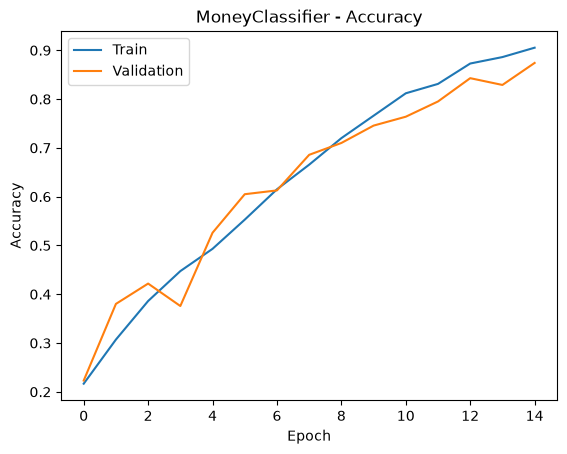

In [6]:
plt.plot(train_accuracies, label="Train")
plt.plot(val_accuracies, label="Validation")

plt.title("MoneyClassifier - Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.show()